In [3]:
#importing packages
import pandas as pd
import csv
import sqlite3
from sqlite3 import Error
!pip install aif360
!pip install pandas numpy scikit-learn matplotlib seaborn
!pip install BlackBoxAuditing

In [18]:
import numpy as np
import pandas as pd

#importing the ACM
print("Adult")
Adult_df = pd.read_csv(
    filepath_or_buffer='adult.csv'
)

Compas_df = pd.read_csv("compas-scores.csv")

print(Compas_df.columns.tolist())

german_df = pd.read_csv(
    'german.data',
    sep=r'\s+',
    header=None
)

columns = [
    'checking_account',
    'duration',
    'credit_history',
    'purpose',
    'credit_amount',
    'savings',
    'employment',
    'installment_rate',
    'personal_status_sex',
    'other_debtors',
    'residence_since',
    'property',
    'age',
    'other_installment_plans',
    'housing',
    'existing_credits',
    'job',
    'liable_people',
    'telephone',
    'foreign_worker',
    'credit_risk'
]

german_df.columns = columns

Compas_df.head()

Adult
['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob', 'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score', 'juv_misd_count', 'juv_other_count', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number', 'c_offense_date', 'c_arrest_date', 'c_days_from_compas', 'c_charge_degree', 'c_charge_desc', 'is_recid', 'num_r_cases', 'r_case_number', 'r_charge_degree', 'r_days_from_arrest', 'r_offense_date', 'r_charge_desc', 'r_jail_in', 'r_jail_out', 'is_violent_recid', 'num_vr_cases', 'vr_case_number', 'vr_charge_degree', 'vr_offense_date', 'vr_charge_desc', 'v_type_of_assessment', 'v_decile_score', 'v_score_text', 'v_screening_date', 'type_of_assessment', 'decile_score.1', 'score_text', 'screening_date']


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,vr_offense_date,vr_charge_desc,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,type_of_assessment,decile_score.1,score_text,screening_date
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,NaN,NaN,Risk of Violence,1,Low,2013-08-14,Risk of Recidivism,1,Low,2013-08-14
1,2,michael ryan,michael,ryan,2014-12-31,Male,1985-02-06,31,25 - 45,Caucasian,...,NaN,NaN,Risk of Violence,2,Low,2014-12-31,Risk of Recidivism,5,Medium,2014-12-31
2,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,2013-07-05,Felony Battery (Dom Strang),Risk of Violence,1,Low,2013-01-27,Risk of Recidivism,3,Low,2013-01-27
3,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,NaN,NaN,Risk of Violence,3,Low,2013-04-14,Risk of Recidivism,4,Low,2013-04-14
4,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,NaN,NaN,Risk of Violence,6,Medium,2013-01-13,Risk of Recidivism,8,High,2013-01-13


In [20]:
# ---------------------------------------
# ADULT DATASET
# ---------------------------------------

adult = Adult_df.copy()

# Clean column names
adult.columns = adult.columns.str.strip()

# Identify target column
target_col = next(
    (c for c in adult.columns
     if c.lower() in ["income", "class"]),
    None
)

if target_col is None:
    raise ValueError("Could not find Adult income column.")

adult[target_col] = (
    adult[target_col].astype(str).str.strip()
)

adult["label"] = (
    adult[target_col].str.replace(".", "", regex=False)
    .eq(">50K").astype(int)
)

# White = privileged
adult["protected"] = (
    adult["race"].astype(str).str.strip().eq("White")
).astype(int)

# Remove unnecessary columns
adult = adult.drop(columns=[target_col])

# ---------------------------------------
# COMPAS DATASET
# ---------------------------------------

# COMPAS dataset
compas = Compas_df.copy()

# Clean column names
compas.columns = compas.columns.str.strip().str.lower()

# Keep Black and White individuals
compas = compas[
    compas["race"].isin(["African-American", "Caucasian"])
].copy()

# Remove missing recidivism outcomes
compas = compas[
    compas["is_recid"].notna()
].copy()

# Favorable outcome: no recidivism
compas["label"] = (
    compas["is_recid"] == 0
).astype(int)

# White = privileged
compas["protected"] = (
    compas["race"] == "Caucasian"
).astype(int)

# ---------------------------------------
# GERMAN CREDIT DATASET
# ---------------------------------------

# German Credit
german = german_df.copy()

# Check original target values
print(german["credit_risk"].value_counts())

# Correct target encoding
german["label"] = (
    german["credit_risk"].astype(str) == "1"
).astype(int)

# Male = privileged
german["protected"] = (
    german["personal_status_sex"].isin(
        ["A91", "A93", "A94"]
    )
).astype(int)

# Remove original target
german = german.drop(
    columns=["credit_risk"]
)

print("\nCorrected German target:")
print(german["label"].value_counts())

# ---------------------------------------
# REMOVE ORIGINAL TARGET COLUMNS
# ---------------------------------------

print("Datasets prepared:")
print("Adult:", adult.shape)
print("COMPAS:", compas.shape)
print("German:", german.shape)

credit_risk
1    700
2    300
Name: count, dtype: int64

Corrected German target:
label
1    700
0    300
Name: count, dtype: int64
Datasets prepared:
Adult: (32561, 16)
COMPAS: (9898, 49)
German: (1000, 22)


In [21]:
# Adult
adult = adult.drop(
    columns=["fnlwgt", "education_num"],
    errors="ignore"
)

# COMPAS
compas = compas.drop(
    columns=[
        "id", "name", "first", "last",
        "dob", "c_case_number", "r_case_number",
        "compas_screening_date",
        "c_offense_date", "c_arrest_date",
        "r_offense_date"
    ],
    errors="ignore"
)

# German
german = german.drop(
    columns=["personal_status_sex"],
    errors="ignore"
)

In [22]:
from sklearn.neighbors import NearestNeighbors

def calculate_fairness(y, protected, X, k=5):

    y = np.asarray(y).astype(int)
    protected = np.asarray(protected).astype(int)
    X = np.asarray(X, dtype=float)

    # Privileged and unprivileged groups
    privileged = protected == 1
    unprivileged = protected == 0

    # Probability of favorable outcomes
    p_privileged = np.mean(y[privileged])
    p_unprivileged = np.mean(y[unprivileged])

    # Demographic Parity Difference
    dp_diff = p_unprivileged - p_privileged

    # Disparate Impact Ratio
    dir_value = (
        p_unprivileged / p_privileged
        if p_privileged > 0 else np.nan
    )

    # Consistency
    # Consistency
    if len(X) > k:

        neighbors = NearestNeighbors(
            n_neighbors=k + 1,
            algorithm="kd_tree"
        )

        neighbors.fit(X)

        indices = neighbors.kneighbors(
            X,
            return_distance=False
        )

        indices = indices[:, 1:]

        neighbor_labels = y[indices]

        consistency = 1 - np.mean(
            np.abs(
                y - np.mean(neighbor_labels, axis=1)
            )
        )

    else:
        consistency = np.nan

    return {
        "DP_Diff": dp_diff,
        "DIR": dir_value,
        "Consistency": consistency
    }

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

def original_metrics(df, sample_size=5000):

    # Sample the dataset if it is too large
    if len(df) > sample_size:
        df = df.sample(
            n=sample_size,
            random_state=42
        )

    # Separate features
    X = df.drop(columns=["label", "protected"])

    # Keep numerical features only for consistency
    X = X.select_dtypes(include=["number"])

    # Fill missing values
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(X.median())
    X = X.fillna(0)

    # Scale features
    X = StandardScaler().fit_transform(X)

    return calculate_fairness(
        y=df["label"].values,
        protected=df["protected"].values,
        X=X
    )


original_results = {}

for name, df in {
    "Adult": adult,
    "COMPAS": compas,
    "German": german
}.items():

    print("Processing:", name)

    original_results[name] = original_metrics(df)

original_results_df = pd.DataFrame(
    original_results
).T

print("\nOriginal fairness metrics:")
print(original_results_df.round(4))

Processing: Adult
Processing: COMPAS
Processing: German

Original fairness metrics:
        DP_Diff     DIR  Consistency
Adult   -0.0841  0.6552       0.7713
COMPAS  -0.0947  0.8588       0.9827
German  -0.0748  0.8966       0.6118


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import DisparateImpactRemover

In [25]:
from sklearn.preprocessing import OrdinalEncoder

def prepare_dataset(df):

    X = df.drop(
        columns=["label", "protected"]
    ).copy()

    # Separate categorical and numerical columns
    categorical_cols = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    numerical_cols = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    # Encode categorical variables
    if categorical_cols:

        encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
            max_categories=20,
            dtype=np.float32
        )

        X[categorical_cols] = encoder.fit_transform(
            X[categorical_cols].fillna("Missing").astype(str)
        )

    # Handle missing values
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    # Use smaller data type
    X = X.astype(np.float32)

    # Add protected attribute
    X["protected"] = df["protected"].values.astype(np.float32)

    return X, df["label"].astype(int).values

In [26]:
def run_experiment(df, dataset_name):

    print("\n" + "=" * 60)
    print("DATASET:", dataset_name)
    print("=" * 60)

    # Reduce dataset size
    if len(df) > 5000:
        df = df.sample(
            n=5000,
            random_state=42
        ).reset_index(drop=True)

    # -----------------------------------
    # 1. Prepare features and labels
    # -----------------------------------

    X, y = prepare_dataset(df)

    protected = X["protected"].values

    # -----------------------------------
    # 2. Stratified train/test split
    # -----------------------------------

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # -----------------------------------
    # 3. Create AIF360 datasets
    # -----------------------------------

    train_df = X_train.copy()
    train_df["label"] = y_train

    test_df = X_test.copy()
    test_df["label"] = y_test

    train_aif = BinaryLabelDataset(
        df=train_df,
        label_names=["label"],
        protected_attribute_names=["protected"],
        favorable_label=1,
        unfavorable_label=0
    )

    test_aif = BinaryLabelDataset(
        df=test_df,
        label_names=["label"],
        protected_attribute_names=["protected"],
        favorable_label=1,
        unfavorable_label=0
    )

    # -----------------------------------
    # 4. Original test fairness metrics
    # -----------------------------------

    scaler_original = StandardScaler()

    X_test_original = X_test.drop(
        columns=["protected"]
    )

    X_test_original_scaled = scaler_original.fit_transform(
        X_test_original
    )

    before = calculate_fairness(
        y=y_test,
        protected=X_test["protected"].values,
        X=X_test_original_scaled
    )

    # -----------------------------------
    # 5. Apply Disparate Impact Remover
    # -----------------------------------

    dir_algorithm = DisparateImpactRemover(
    repair_level=1.0,
    sensitive_attribute="protected"
    )

    # Repair training data
    train_repaired = dir_algorithm.fit_transform(train_aif)

    # Repair held-out test data
    test_repaired = dir_algorithm.fit_transform(test_aif)

    # Convert AIF360 datasets back to pandas
    train_repaired_df = train_repaired.convert_to_dataframe()[0]
    test_repaired_df = test_repaired.convert_to_dataframe()[0]

    # -----------------------------------
    # 6. Extract repaired features
    # -----------------------------------

    X_train_repaired = train_repaired_df.drop(
        columns=["label", "protected"]
    )

    X_test_repaired = test_repaired_df.drop(
        columns=["label", "protected"]
    )

    y_train_repaired = (
        train_repaired_df["label"].astype(int).values
    )

    # The original labels are retained by DIR
    y_test_repaired = (
        test_repaired_df["label"].astype(int).values
    )

    # -----------------------------------
    # 7. Scale repaired features
    # -----------------------------------

    scaler = StandardScaler()

    X_train_repaired = scaler.fit_transform(
        X_train_repaired
    )

    X_test_repaired = scaler.transform(
        X_test_repaired
    )

    # -----------------------------------
    # 8. Train Logistic Regression
    # -----------------------------------

    classifier = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    classifier.fit(
        X_train_repaired,
        y_train_repaired
    )

    # -----------------------------------
    # 9. Predict on held-out test data
    # -----------------------------------

    y_pred = classifier.predict(X_test_repaired)

    # -----------------------------------
    # 10. Calculate predictive performance
    # -----------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        y_pred
    )

    # -----------------------------------
    # 11. Calculate fairness after mitigation
    # -----------------------------------

    after = calculate_fairness(
        y=y_pred,
        protected=test_repaired_df["protected"].values,
        X=X_test_repaired
    )

    # -----------------------------------
    # 12. Store results
    # -----------------------------------

    results = {
        "Dataset": dataset_name,

        "Before_DP_Diff": before["DP_Diff"],
        "After_DP_Diff": after["DP_Diff"],

        "Before_DIR": before["DIR"],
        "After_DIR": after["DIR"],

        "Before_Consistency": before["Consistency"],
        "After_Consistency": after["Consistency"],

        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_accuracy
    }

    return results

In [29]:
for name, df in {
    "Adult": adult,
    "COMPAS": compas,
    "German": german
}.items():

    print("\n", name)
    print(df["label"].value_counts())


 Adult
label
0    24720
1     7841
Name: count, dtype: int64

 COMPAS
label
1    6055
0    3843
Name: count, dtype: int64

 German
label
1    700
0    300
Name: count, dtype: int64


In [30]:
datasets = {
    "Adult": adult,
    "COMPAS": compas,
    "German": german
}

results = []

for name, df in datasets.items():

    result = run_experiment(df, name)
    results.append(result)

    pd.DataFrame(results).to_csv(
        "fairness_results.csv",
        index=False
    )

    import gc
    gc.collect()

results_df = pd.DataFrame(results)

print("\nFINAL RESULTS")
print(results_df.round(4).to_string(index=False))


DATASET: Adult

DATASET: COMPAS

DATASET: German

FINAL RESULTS
Dataset  Before_DP_Diff  After_DP_Diff  Before_DIR  After_DIR  Before_Consistency  After_Consistency  Accuracy  Balanced_Accuracy
  Adult         -0.0400        -0.0343      0.8325     0.7318              0.7744             0.9338     0.834             0.6844
 COMPAS         -0.0767        -0.0658      0.8838     0.8983              0.9538             0.9502     0.992             0.9930
 German         -0.0476        -0.1262      0.9333     0.8301              0.6720             0.7730     0.735             0.6821


In [31]:
comparison = results_df[
    [
        "Dataset",
        "Before_DP_Diff",
        "After_DP_Diff",
        "Before_DIR",
        "After_DIR",
        "Before_Consistency",
        "After_Consistency"
    ]
].copy()

print("\nFAIRNESS COMPARISON")
print(comparison.round(4).to_string(index=False))


FAIRNESS COMPARISON
Dataset  Before_DP_Diff  After_DP_Diff  Before_DIR  After_DIR  Before_Consistency  After_Consistency
  Adult         -0.0400        -0.0343      0.8325     0.7318              0.7744             0.9338
 COMPAS         -0.0767        -0.0658      0.8838     0.8983              0.9538             0.9502
 German         -0.0476        -0.1262      0.9333     0.8301              0.6720             0.7730


In [32]:
comparison["DP_Diff_Improvement"] = (
    comparison["Before_DP_Diff"].abs()
    - comparison["After_DP_Diff"].abs()
)

comparison["DIR_Improvement"] = (
    (1 - comparison["Before_DIR"]).abs()
    - (1 - comparison["After_DIR"]).abs()
)

comparison["Consistency_Improvement"] = (
    comparison["After_Consistency"]
    - comparison["Before_Consistency"]
)

print("\nFAIRNESS IMPROVEMENTS")
print(comparison.round(4).to_string(index=False))


FAIRNESS IMPROVEMENTS
Dataset  Before_DP_Diff  After_DP_Diff  Before_DIR  After_DIR  Before_Consistency  After_Consistency  DP_Diff_Improvement  DIR_Improvement  Consistency_Improvement
  Adult         -0.0400        -0.0343      0.8325     0.7318              0.7744             0.9338               0.0057          -0.1007                   0.1594
 COMPAS         -0.0767        -0.0658      0.8838     0.8983              0.9538             0.9502               0.0108           0.0145                  -0.0036
 German         -0.0476        -0.1262      0.9333     0.8301              0.6720             0.7730              -0.0786          -0.1032                   0.1010


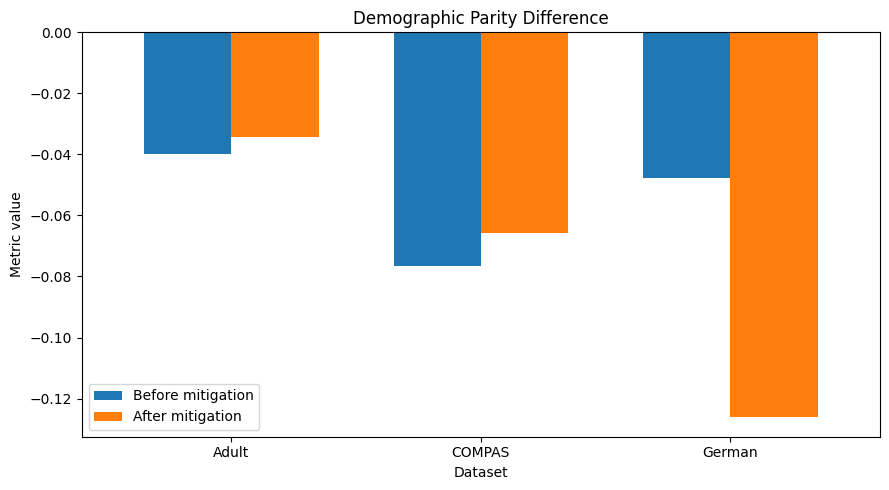

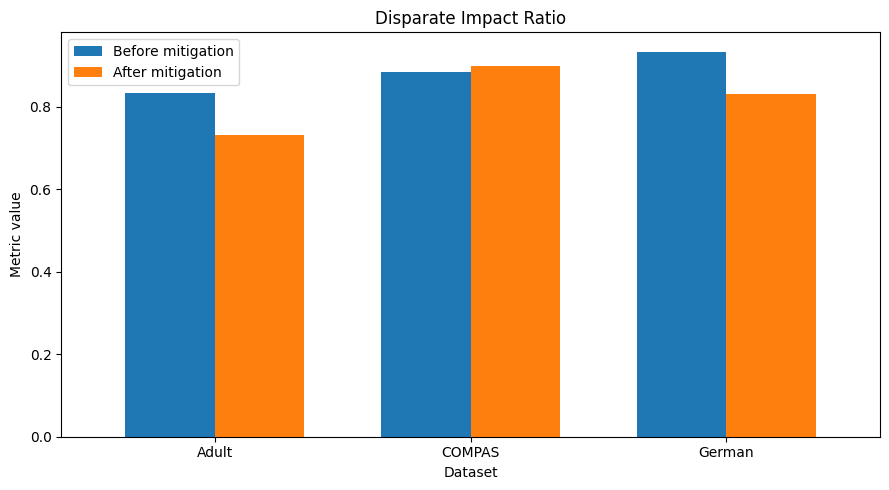

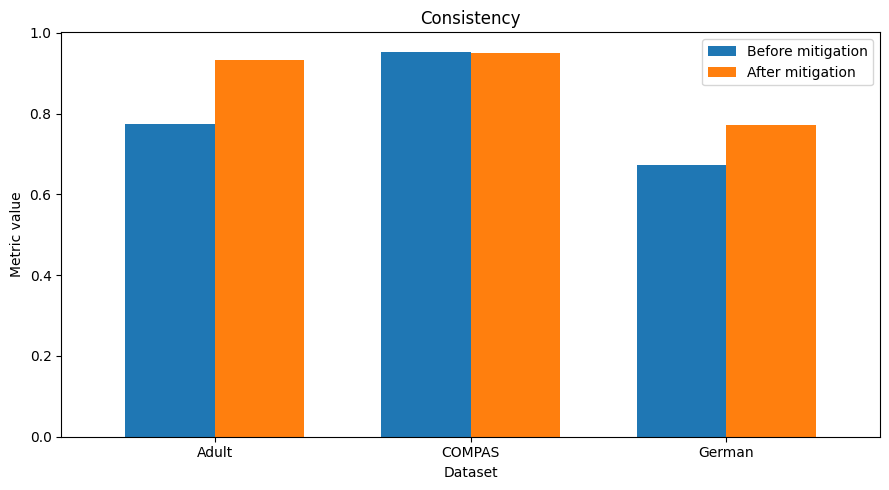

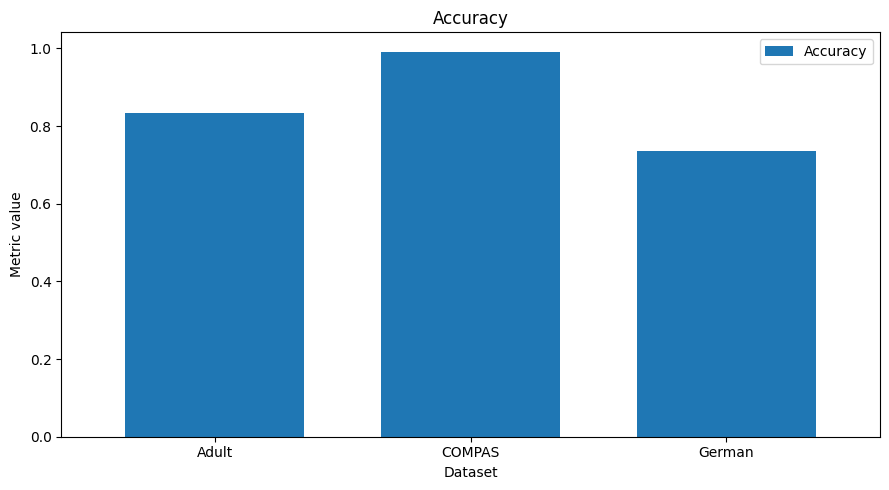

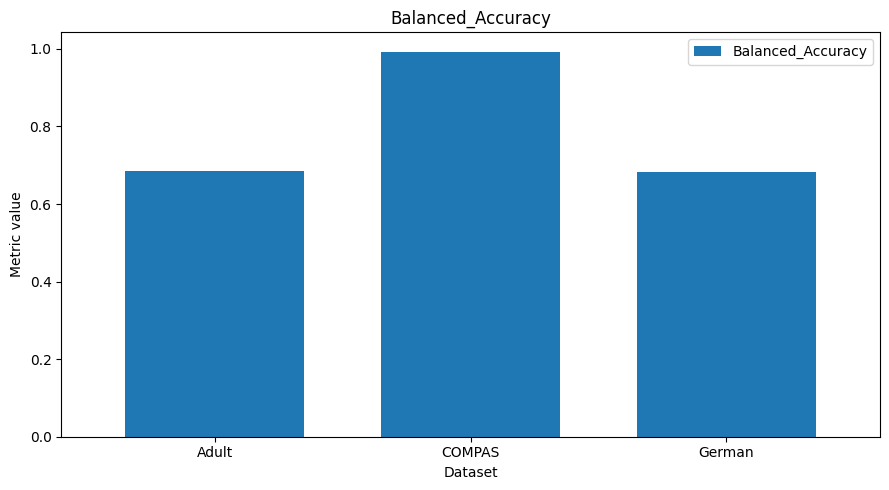

In [40]:
import matplotlib.pyplot as plt
%matplotlib inline

metrics = [
    ("Before_DP_Diff", "After_DP_Diff",
     "Demographic Parity Difference"),

    ("Before_DIR", "After_DIR",
     "Disparate Impact Ratio"),

    ("Before_Consistency", "After_Consistency",
     "Consistency")
]

for before_col, after_col, title in metrics:

    comparison_plot = results_df.set_index("Dataset")

    ax = comparison_plot[
        [before_col, after_col]
    ].plot(
        kind="bar",
        figsize=(9, 5),
        width=0.7
    )

    ax.set_title(title)
    ax.set_ylabel("Metric value")
    ax.set_xlabel("Dataset")
    ax.legend(["Before mitigation", "After mitigation"])

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

metrics = [
    ("Accuracy",
     "Accuracy"),

    ("Balanced_Accuracy",
     "Balanced_Accuracy")
]

for before_col, title in metrics:

    comparison_plot = results_df.set_index("Dataset")

    ax = comparison_plot[
        [before_col]
    ].plot(
        kind="bar",
        figsize=(9, 5),
        width=0.7
    )

    ax.set_title(title)
    ax.set_ylabel("Metric value")
    ax.set_xlabel("Dataset")

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()